# Équilibrage des classes : `class_weight` contre Oversampling et Undersampling

**Question** : sur-échantillonner ou sous-échantillonner les classes fait-il mieux que `class_weight="balanced"`, que nous utilisons déjà ?

**Rappel important** : le macro-F1 n'équilibre rien à l'entraînement. C'est un critère de **sélection et d'évaluation** (il donne le même poids aux trois classes). `class_weight` agit, lui, sur la **fonction de perte** pendant l'apprentissage. Les deux sont complémentaires. Notons aussi que KNN n'a pas de `class_weight` : il n'est aujourd'hui pas équilibré du tout.

## Protocole

| Stratégie | Ce qui change |
|---|---|
| **Aucun** | référence : classes telles quelles |
| **class_weight** | solution actuelle : poids inversement proportionnels aux effectifs (SVM, RF) |
| **RandomUnderSampler** | on retire au hasard des lignes des classes fréquentes jusqu'à égaler la plus rare |
| **SMOTE** | on fabrique des lignes synthétiques de la classe rare par interpolation entre voisins |

- **Données** : l'échantillon stratifié de 30 000 lignes, avec **les mêmes 3 plis chronologiques** qu'en section 3 de `05`.
- **Le rééchantillonnage ne touche que la partie apprentissage de chaque pli**, jamais la validation ni le test (il est dans un `Pipeline` d'`imbalanced-learn`). Rééchantillonner avant de découper ferait fuiter des lignes de validation dans l'apprentissage.
- Avec un rééchantillonnage, `class_weight` est désactivé : combiner les deux compenserait deux fois.
- **Hyperparamètres** : ceux choisis pour chaque modèle (fiche `<modele>_echantillon.json`), non ré-optimisés par stratégie. C'est un léger avantage pour `class_weight`, avec lequel ils ont été réglés.
- **Règle de décision fixée avant de voir les résultats** : on garde `class_weight` sauf si une autre stratégie améliore le macro-F1 de validation de plus d'un écart-type entre plis. À gain comparable, on préfère la solution la plus simple et la moins coûteuse.
- Le **test** n'intervient qu'à la fin, pour rapporter les chiffres, pas pour choisir.

Prérequis : `pip install imbalanced-learn`.

In [ ]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

# Dossier des données
#BASE = os.environ.get("DM_BASE", r"C:\Users\chahi\Desktop\DM-Weather-framework\data")
BASE = os.environ.get("DM_BASE", r"D:\M2\Data Mining\DM-Weather-framework\data")
SUP_DIR = os.path.join(BASE, "processed", "transformed", "supervised")
#RES_DIR = r"C:\Users\chahi\Desktop\DM-Weather-framework\results"
#RES_DIR = os.path.join(BASE, "results")
RES_DIR = r"D:\M2\Data Mining\DM-Weather-framework\results"
RESULTAT = RES_DIR
TABLES_DIR = os.path.join(RESULTAT, "tables")
FIGURES_DIR = os.path.join(RESULTAT, "figures")
MODELES_DIR = os.path.join(RESULTAT, "models")
os.makedirs(TABLES_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(MODELES_DIR, exist_ok=True)

LABELS = ["Low", "Medium", "High"]   # les 3 classes
SEED = 42                            # pour retrouver les mêmes résultats à chaque exécution


CONFIG = "reduit_sans_year"                     # configuration testée (une seule suffit pour cette comparaison)
MODELES = ["knn", "svm", "rf"]
STRATEGIES = ["aucun", "class_weight", "undersampling", "smote"]
NOM_STRATEGIE = {"aucun": "Aucun", "class_weight": "class_weight (actuel)",
                 "undersampling": "RandomUnderSampler", "smote": "SMOTE"}
EVALUER_TEST = True                             # False = validation seulement (beaucoup plus rapide)

In [7]:
for nom in MODELES:
    chemin = os.path.join(MODELES_DIR, CONFIG, nom + "_echantillon.json")

    with open(chemin, encoding="utf-8") as f:
        fiche = json.load(f)

    print(f"\n{nom.upper()}")
    print("Clés disponibles :", list(fiche.keys()))


KNN
Clés disponibles : ['nom', 'config', 'jeu', 'avec_year', 'variables', 'donnees', 'parametres', 'macro_F1_validation', 'temps_fit_s']

SVM
Clés disponibles : ['nom', 'config', 'jeu', 'avec_year', 'variables', 'donnees', 'parametres', 'macro_F1_validation', 'temps_fit_s']

RF
Clés disponibles : ['nom', 'config', 'jeu', 'avec_year', 'variables', 'donnees', 'parametres', 'macro_F1_validation', 'temps_fit_s']


In [8]:
sample = pd.read_parquet(os.path.join(SUP_DIR, "train_sample_30k.parquet"))
#sample = pd.read_parquet(os.path.join(SUP_DIR, "train_supervised.parquet"))
test   = pd.read_parquet(os.path.join(SUP_DIR, "test_supervised.parquet"))

# Conversion des types (cible -> str ,  )
for d in (sample, test):
    d["classe"] = d["classe"].astype(str)
    d["date"] = pd.to_datetime(d["date"])

# init de l'index : C'est utile parce que les indices générés dans les plis seront ensuite utilisés avec iloc
sample = sample.reset_index(drop=True)
y_s, y_test = sample["classe"].to_numpy(), test["classe"].to_numpy()

# Les mêmes 3 plis chronologiques que dans 05 (un mois d'écart entre apprentissage et validation)
mois = np.sort(sample["date"].unique())
plis = []
for tr, va in TimeSeriesSplit(n_splits=3, gap=1).split(mois):
    plis.append((np.where(sample["date"].isin(mois[tr]))[0], np.where(sample["date"].isin(mois[va]))[0]))

# Variables et hyperparamètres de chaque modèle : lus dans les fiches enregistrées par 05
CLASSES = {"knn": KNeighborsClassifier, "svm": SVC, "rf": RandomForestClassifier}
PARAMS, variables = {}, None
for nom in MODELES:
    chemin = os.path.join(MODELES_DIR, CONFIG, nom + "_echantillon.json")
    if not os.path.exists(chemin):
        raise FileNotFoundError("Fiche introuvable : " + chemin + " (lance d'abord la section 5 de 05_Supervised_Learning)")
    with open(chemin, encoding="utf-8") as f:
        fiche = json.load(f)

    PARAMS[nom] = fiche["parametres"]

    variables = fiche["variables"]
X = sample[variables]
print("Configuration :", CONFIG, "|", len(variables), "variables")
CLES = ("n_neighbors", "weights", "C", "gamma", "max_depth", "min_samples_leaf", "class_weight")
for nom in MODELES:
    print(" ", nom, ":", {k: PARAMS[nom][k] for k in CLES if k in PARAMS[nom]})

Configuration : reduit_sans_year | 11 variables
  knn : {'n_neighbors': 15, 'weights': 'distance'}
  svm : {'C': 10, 'gamma': 'scale'}
  rf : {'max_depth': None, 'min_samples_leaf': 1}


**validation chronologique**

Les données climatiques sont temporelles.

Il serait donc incorrect de mélanger aléatoirement les observations pour créer les ensembles d'entraînement et de validation.

On veut respecter l'ordre temporel :
- Apprendre sur le passé.
- Valider sur une période future


**Construction des plis temporels**

La division est d'abord effectuée sur les mois, à l'aide de `TimeSeriesSplit(n_splits=3, gap=1)`, afin de respecter l'ordre chronologique des données.

Pour chaque pli, les mois sont répartis en trois groupes : entraînement (Train), un mois d'écart (Gap) et validation (Validation).

Ensuite, les indices des lignes correspondant aux mois de chaque groupe sont récupérés à l'aide de `np.where()`. Cela permet de retrouver les observations météorologiques associées à chaque période et de constituer les ensembles d'entraînement et de validation.

## 1. Ce que fait chaque méthode aux effectifs (apprentissage du pli 3)

In [9]:
# la partie entraînement du troisième pli
idx_tr, _ = plis[-1]
y_tr = y_s[idx_tr]
lignes = [{"methode": "Avant (réel)", **pd.Series(y_tr).value_counts().reindex(LABELS).to_dict()}]
for nom, ech in (("RandomUnderSampler", RandomUnderSampler(random_state=SEED)), ("SMOTE", SMOTE(random_state=SEED))):
    _, y_r = ech.fit_resample(X.iloc[idx_tr], y_tr)
    lignes.append({"methode": nom, **pd.Series(y_r).value_counts().reindex(LABELS).to_dict()})

effectifs = pd.DataFrame(lignes).set_index("methode")
effectifs["total"] = effectifs.sum(axis=1)
display(effectifs)

,Low,Medium,High,total
methode,,,,
Avant (réel),3515,9705,9153,22373
RandomUnderSampler,3515,3515,3515,10545
SMOTE,9705,9705,9705,29115


***Remarque :*** les effectifs présentés correspondent uniquement aux données d'entraînement du dernier pli temporel (22373), et non à la totalité des 30 000 observations. L'équilibrage sera ensuite appliqué séparément à chaque ensemble d'entraînement pendant la validation croisée, sans modifier les données de validation.

## 2. Construction des modèles pour chaque stratégie

In [14]:
def construire(nom_modele, strategie):
    """Renvoie le modèle (ou un Pipeline avec rééchantillonnage), ou None si la stratégie n'existe pas pour ce modèle."""
    params = dict(PARAMS[nom_modele])
    if nom_modele == "svm":
        params["class_weight"] = "balanced"

    elif nom_modele == "rf":
        params["class_weight"] = "balanced_subsample"

    if strategie == "class_weight":
        if nom_modele == "knn":
            return None
    else:
        # Désactiver class_weight pour isoler l'effet du rééchantillonnage
        if nom_modele in ["svm", "rf"]:
            params["class_weight"] = None                        # pas de double compensation

    # construction des model
    modele = CLASSES[nom_modele](**params)

    """
    Le pipeline réalise automatiquement deux opérations pendant l'entraînement :
      1. Rééquilibrer les données d'entraînement.
      2. Entraîner le modèle sur les données rééquilibrées.
    """

    if strategie == "undersampling":
        return ImbPipeline([("echantillonnage", RandomUnderSampler(random_state=SEED)), ("modele", modele)])
    if strategie == "smote":
        return ImbPipeline([("echantillonnage", SMOTE(random_state=SEED)), ("modele", modele)])
    return modele

def metriques(y_vrai, y_pred):
  # Cette fonction est predefinie utiliser pour calcule les métriques nécessaires pour évaluer les modèles.
    p, r, f, _ = precision_recall_fscore_support(y_vrai, y_pred, labels=LABELS, zero_division=0)
    return {"macro_F1": f.mean(), "accuracy": accuracy_score(y_vrai, y_pred),
            "F1_Low": f[0], "F1_Medium": f[1], "F1_High": f[2],
            "precision_Low": p[0], "rappel_Low": r[0], "precision_Medium": p[1],
            "precision_High": p[2],"rappel_Medium": r[1],"rappel_High": r[2]}

**Pourquoi calculer les F1-scores séparément ?**

Parce que le macro-F1 seul ne permet pas de comprendre précisément les performances sur chaque classe. Par exemple, deux modèles peuvent avoir le même macro-F1, mais :
- Le premier détecte mieux Low.
- Le deuxième détecte mieux High.

## 3. Validation chronologique (3 plis) sur l'échantillon

À chaque pli : rééchantillonnage de la partie apprentissage seulement, ajustement, puis score sur la partie validation, intacte.

### Interprétation des résultats

In [15]:
lignes = []
for nom in MODELES:
    for strat in STRATEGIES:
        # Pour chaque combinaison modèle-stratégie, on réalise trois entraînements et évaluations.
        modele = construire(nom, strat)
        if modele is None:
            # cas pour KNN class weights
            continue
        for k, (tr, va) in enumerate(plis, start=1):
            m = clone(modele)
            t0 = time.time()
            m.fit(X.iloc[tr], y_s[tr])
            duree = time.time() - t0
            lignes.append({"modele": nom, "strategie": strat, "pli": k, "temps_fit_s": duree,
                           **metriques(y_s[va], m.predict(X.iloc[va]))})
        print(nom, "|", NOM_STRATEGIE[strat], ": terminé")


# creation du taelau recaituatf :
cv = pd.DataFrame(lignes)

colonnes = [
    "macro_F1", "accuracy",
    "F1_Low", "F1_Medium", "F1_High",
    "precision_Low", "rappel_Low",
    "precision_Medium", "rappel_Medium",
    "precision_High", "rappel_High",
    "temps_fit_s"
]

resume = cv.groupby(
    ["modele", "strategie"]
)[colonnes].mean()

resume["macro_F1_std"] = cv.groupby(
    ["modele", "strategie"]
)["macro_F1"].std()

resume = resume.reindex([
    (m, s)
    for m in MODELES
    for s in STRATEGIES
    if (m, s) in resume.index
])

display(resume.round(4))

# Sauvegarde des résultats de validation.
resume.round(4).to_csv(os.path.join(TABLES_DIR, "equilibrage_validation_" + CONFIG + ".csv"))
cv.round(4).to_csv(os.path.join(TABLES_DIR, "equilibrage_validation_par_pli_" + CONFIG + ".csv"), index=False)

knn | Aucun : terminé
knn | RandomUnderSampler : terminé
knn | SMOTE : terminé
svm | Aucun : terminé
svm | class_weight (actuel) : terminé
svm | RandomUnderSampler : terminé
svm | SMOTE : terminé
rf | Aucun : terminé
rf | class_weight (actuel) : terminé
rf | RandomUnderSampler : terminé
rf | SMOTE : terminé


macro_F1  accuracy  F1_Low  F1_Medium  F1_High  \
modele strategie                                                       
knn    aucun            0.8412    0.8578  0.7732     0.8383   0.9121   
       undersampling    0.8346    0.8446  0.7889     0.8117   0.9033   
       smote            0.8419    0.8531  0.7893     0.8243   0.9122   
svm    aucun            0.8645    0.8798  0.8010     0.8640   0.9284   
       class_weight     0.8625    0.8749  0.8049     0.8547   0.9280   
       undersampling    0.8603    0.8705  0.8106     0.8485   0.9217   
       smote            0.8624    0.8752  0.8040     0.8556   0.9275   
rf     aucun            0.8641    0.8790  0.8009     0.8639   0.9275   
       class_weight     0.8648    0.8804  0.7999     0.8655   0.9289   
       undersampling    0.8602    0.8718  0.8049     0.8506   0.9252   
       smote            0.8632    0.8767  0.8027     0.8590   0.9278   

                      precision_Low  rappel_Low  temps_fit_s  macro_F1_std  
modele strategie                                                            
knn    aucun                 0.8122      0.7462       0.0475        0.0155  
       undersampling         0.7204      0.8800       0.0828        0.0034  
       smote                 0.7292      0.8686       0.5861        0.0022  
svm    aucun                 0.8345      0.7885       2.4368        0.0241  
       class_weight          0.7805      0.8548       2.8528        0.0026  
       undersampling         0.7735      0.8745       0.7625        0.0048  
       smote                 0.7883      0.8439       4.4945        0.0045  
rf     aucun                 0.8260      0.7929       5.9919        0.0131  
       class_weight          0.8346      0.7840       6.3377        0.0209  
       undersampling         0.7648      0.8701       2.9264        0.0063  
       smote                 0.7953      0.8287       8.4183        0.0054

La comparaison des différentes stratégies d'équilibrage sur les trois plis temporels permet de tirer les conclusions suivantes :

- **KNN :** SMOTE obtient le meilleur Macro-F1 (0.8419), mais le gain par rapport à l'absence d'équilibrage (0.8412) est négligeable. RandomUnderSampler améliore légèrement le F1 de la classe Low, mais réduit les performances globales. La stratégie sans équilibrage reste donc préférable.

- **SVM :** l'absence d'équilibrage obtient les meilleurs résultats en Macro-F1 (0.8645) et en Accuracy (0.8798). RandomUnderSampler améliore légèrement le F1 de Low, mais dégrade les performances globales. SMOTE n'apporte pas d'amélioration notable par rapport à `class_weight`.

- **Random Forest :** `class_weight` obtient le meilleur Macro-F1 (0.8648) et la meilleure Accuracy (0.8804). Cependant, son gain par rapport à l'absence d'équilibrage reste très faible. SMOTE et RandomUnderSampler n'apportent pas d'amélioration globale.

#### Analyse complémentaire

- **Détection de la classe Low :** les méthodes de rééchantillonnage améliorent parfois son F1-score, mais cette amélioration ne se traduit pas par un gain global du Macro-F1.
- **Stabilité :** les écarts-types montrent une certaine variabilité entre les plis, particulièrement pour le SVM. Les résultats doivent être interprétés avec prudence, car seuls trois plis sont utilisés.
- **Temps d'entraînement :** SMOTE augmente le coût computationnel, notamment pour Random Forest, sans apporter de gain significatif en performance.

***Remarque:***: macro_F1_std représente l'écart-type du Macro-F1 calculé sur les 3 plis de validation. Il permet de mesurer la stabilité des performances du modèle entre les différents plis.

ALORS, Les méthodes SMOTE et RandomUnderSampler n'apportent pas d'amélioration globale significative par rapport aux stratégies de référence. Nous retenons donc provisoirement :

- **KNN :** aucun équilibrage.
- **SVM :** aucun équilibrage.
- **Random Forest :** `class_weight`.

Ces choix privilégient les stratégies les plus simples tout en conservant de bonnes performances. Ils seront confirmés lors de l'évaluation finale sur le jeu de test.

### Visualisation
La cellule suivante génère deux graphiques pour faciliter la comparaison des stratégies d'équilibrage :

Graphique 1 : comparaison du Macro-F1 moyen des trois modèles selon les stratégies. Les barres d'erreur représentent l'écart-type sur les trois plis et permettent d'observer la stabilité des performances.

Graphique 2 : comparaison de la précision et du rappel de la classe Low afin d'évaluer l'effet des stratégies d'équilibrage sur sa détection.

Les graphiques sont ensuite sauvegardés au format PNG dans le dossier des figures.

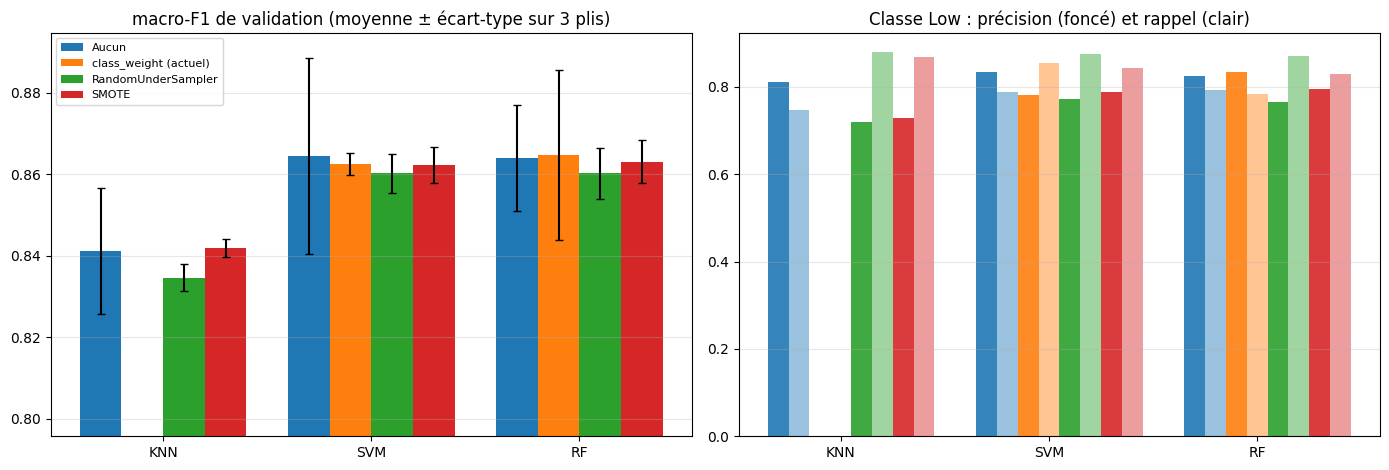

In [21]:
# Création d'une figure contenant deux graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Calcul de la largeur des barres selon le nombre de stratégies
largeur = 0.8 / len(STRATEGIES)

# Parcours de toutes les stratégies d'équilibrage
for j, strat in enumerate(STRATEGIES):

    # Récupération des résultats correspondant à la stratégie actuelle
    # et organisation selon l'ordre des modèles (KNN, SVM, RF)
    sous = resume.xs(strat, level="strategie").reindex(MODELES)

    # Calcul des positions des barres sur l'axe horizontal
    x = np.arange(len(MODELES)) + j * largeur

    # Graphique 1 : Macro-F1 moyen pour chaque modèle et stratégie
    # Les barres d'erreur représentent l'écart-type sur les 3 plis
    axes[0].bar(
        x, sous["macro_F1"], largeur,
        yerr=sous["macro_F1_std"],
        capsize=3,
        label=NOM_STRATEGIE[strat]
    )

    # Graphique 2 : précision et rappel de la classe Low
    # Barre foncée : précision ; barre claire : rappel
    axes[1].bar(
        x - 0.0, sous["precision_Low"], largeur / 2,
        color=f"C{j}", alpha=0.9
    )
    axes[1].bar(
        x + largeur / 2, sous["rappel_Low"], largeur / 2,
        color=f"C{j}", alpha=0.45
    )

# Configuration des axes des deux graphiques
for ax in axes:

    # Positionnement des étiquettes sur l'axe horizontal
    ax.set_xticks(np.arange(len(MODELES)) + 0.4 - largeur / 2)

    # Affichage des noms des modèles en majuscules
    ax.set_xticklabels([m.upper() for m in MODELES])

    # Ajout d'une grille horizontale pour faciliter la lecture
    ax.grid(axis="y", alpha=0.3)

# Calcul de la limite inférieure du graphique Macro-F1
# en tenant compte de la moyenne et de l'écart-type
bas = (resume["macro_F1"] - resume["macro_F1_std"]).min()

# Ajustement des limites de l'axe vertical du premier graphique
axes[0].set_ylim(
    max(0, bas - 0.03),
    min(1, resume["macro_F1"].max() + 0.03)
)

# Ajout du titre et de la légende du premier graphique
axes[0].set_title("macro-F1 de validation (moyenne ± écart-type sur 3 plis)")
axes[0].legend(fontsize=8)

# Ajout du titre du deuxième graphique
axes[1].set_title("Classe Low : précision (foncé) et rappel (clair)")

# Ajustement automatique des espacements entre les éléments
plt.tight_layout()

# Sauvegarde de la figure au format PNG dans le dossier des figures
plt.savefig(
    os.path.join(FIGURES_DIR, "equilibrage_validation_" + CONFIG + ".png"),
    dpi=150,
    bbox_inches="tight"
)

# Affichage des deux graphiques
plt.show()

In [13]:
for nom in MODELES:
    print(f"\n{nom.upper()}")
    print(PARAMS[nom])


KNN
{'n_neighbors': 15, 'weights': 'distance'}

SVM
{'C': 10, 'gamma': 'scale'}

RF
{'max_depth': None, 'min_samples_leaf': 1}


## 4. Verdict selon la règle fixée au départ

Référence : `class_weight` (SVM, RF) ; pour KNN, qui n'en a pas, « Aucun ». Une stratégie est retenue seulement si son macro-F1 de validation dépasse celui de la référence de plus d'un écart-type entre plis.

In [20]:
# Comparaison des stratégies à partir des mêmes plis
scores = cv.pivot(
    index=["modele", "pli"],
    columns="strategie",
    values="macro_F1"
)

for nom in MODELES:
    ref = "class_weight" if nom != "knn" else "aucun"
    print(f"\n--- {nom.upper()} (référence : {NOM_STRATEGIE[ref]})")
    for strat in STRATEGIES:
        if strat == ref or strat not in scores.columns:
            continue
        differences = (
            scores.loc[nom, strat] -
            scores.loc[nom, ref]
        )
        gain_moyen = differences.mean()
        ecart_type = differences.std()
        if gain_moyen > ecart_type:
            verdict = "Amélioration supérieure à un écart-type"
        elif gain_moyen < -ecart_type:
            verdict = "Dégradation supérieure à un écart-type"
        else:
            verdict = "Résultats proches"

        print(
            f"{NOM_STRATEGIE[strat]:<22}"
            f" Gain moyen : {gain_moyen:+.4f}"
            f" | Écart-type des différences : {ecart_type:.4f}"
            f" | {verdict}"
        )


--- KNN (référence : Aucun)
class_weight (actuel)  Gain moyen : +nan | Écart-type des différences : nan | Résultats proches
RandomUnderSampler     Gain moyen : -0.0066 | Écart-type des différences : 0.0174 | Résultats proches
SMOTE                  Gain moyen : +0.0007 | Écart-type des différences : 0.0160 | Résultats proches

--- SVM (référence : class_weight (actuel))
Aucun                  Gain moyen : +0.0020 | Écart-type des différences : 0.0217 | Résultats proches
RandomUnderSampler     Gain moyen : -0.0022 | Écart-type des différences : 0.0069 | Résultats proches
SMOTE                  Gain moyen : -0.0002 | Écart-type des différences : 0.0018 | Résultats proches

--- RF (référence : class_weight (actuel))
Aucun                  Gain moyen : -0.0007 | Écart-type des différences : 0.0082 | Résultats proches
RandomUnderSampler     Gain moyen : -0.0045 | Écart-type des différences : 0.0264 | Résultats proches
SMOTE                  Gain moyen : -0.0016 | Écart-type des différences

## 5. Test (pour rapporter, pas pour choisir)

Chaque modèle est ajusté sur tout l'échantillon (30 000 lignes) avec chaque stratégie, puis évalué une fois sur le test.


Pour chaque combinaison de modèle et de stratégie, le modèle est entraîné sur l'ensemble des données d'entraînement, puis utilisé pour prédire les classes du jeu de test.

Les performances sont mesurées à l'aide des différentes métriques (Macro-F1, Accuracy, F1-score par classe, précision et rappel), ainsi que du temps d'entraînement et de prédiction.

Les résultats sont ensuite regroupés dans un tableau récapitulatif et sauvegardés au format CSV.

**Remarque :** le jeu de test reste indépendant de l'entraînement et de la sélection des stratégies. Il sert à évaluer les performances des modèles sur des données non utilisées pendant leur apprentissage.

In [ ]:
lignes_t = []
Xtest = test[variables]
for nom in MODELES:
    for strat in STRATEGIES:
        modele = construire(nom, strat)
        if modele is None:
            continue
        t0 = time.time(); modele.fit(X, y_s); t_fit = time.time() - t0
        t0 = time.time(); y_pred = modele.predict(Xtest); t_pred = time.time() - t0
        lignes_t.append({"modele": nom, "strategie": strat, **metriques(y_test, y_pred),
                            "temps_fit_s": t_fit, "temps_pred_s": t_pred})
        print(nom, "|", NOM_STRATEGIE[strat], ": macro-F1 test =", round(lignes_t[-1]["macro_F1"], 4))
res_test = pd.DataFrame(lignes_t).set_index(["modele", "strategie"])
display(res_test.round(4))
res_test.round(4).to_csv(os.path.join(TABLES_DIR, "equilibrage_test_" + CONFIG + ".csv"))

knn | Aucun : macro-F1 test = 0.8667
knn | RandomUnderSampler : macro-F1 test = 0.8569
knn | SMOTE : macro-F1 test = 0.8617
svm | Aucun : macro-F1 test = 0.884
svm | class_weight (actuel) : macro-F1 test = 0.8844
svm | RandomUnderSampler : macro-F1 test = 0.8819
svm | SMOTE : macro-F1 test = 0.8853
rf | Aucun : macro-F1 test = 0.8646
rf | class_weight (actuel) : macro-F1 test = 0.8668
rf | RandomUnderSampler : macro-F1 test = 0.8637
rf | SMOTE : macro-F1 test = 0.8676


macro_F1  accuracy  F1_Low  F1_Medium  F1_High  \
modele strategie                                                       
knn    aucun            0.8667    0.8899  0.7990     0.8629   0.9383   
       undersampling    0.8569    0.8773  0.7989     0.8368   0.9351   
       smote            0.8617    0.8836  0.7984     0.8463   0.9405   
svm    aucun            0.8840    0.8986  0.8420     0.8742   0.9360   
       class_weight     0.8844    0.8972  0.8487     0.8668   0.9377   
       undersampling    0.8819    0.8944  0.8471     0.8634   0.9353   
       smote            0.8853    0.8979  0.8501     0.8679   0.9378   
rf     aucun            0.8646    0.8838  0.8064     0.8573   0.9301   
       class_weight     0.8668    0.8864  0.8079     0.8607   0.9319   
       undersampling    0.8637    0.8806  0.8134     0.8471   0.9306   
       smote            0.8676    0.8854  0.8143     0.8561   0.9325   

                      precision_Low  rappel_Low  temps_fit_s  temps_pred_s  
modele strategie                                                            
knn    aucun                 0.8148      0.7838       0.1100       17.9869  
       undersampling         0.7064      0.9193       0.1654       13.7082  
       smote                 0.7178      0.8993       0.9349       19.5995  
svm    aucun                 0.8437      0.8402       9.5325       63.2899  
       class_weight          0.7698      0.9456      10.5049       68.6641  
       undersampling         0.7655      0.9481       1.9082       33.3498  
       smote                 0.7747      0.9418      14.8058       83.5241  
rf     aucun                 0.7963      0.8166      12.9648        1.2826  
       class_weight          0.8072      0.8087      13.7703        1.1028  
       undersampling         0.7354      0.9100       5.4363        0.9675  
       smote                 0.7683      0.8661      20.1649        1.1189

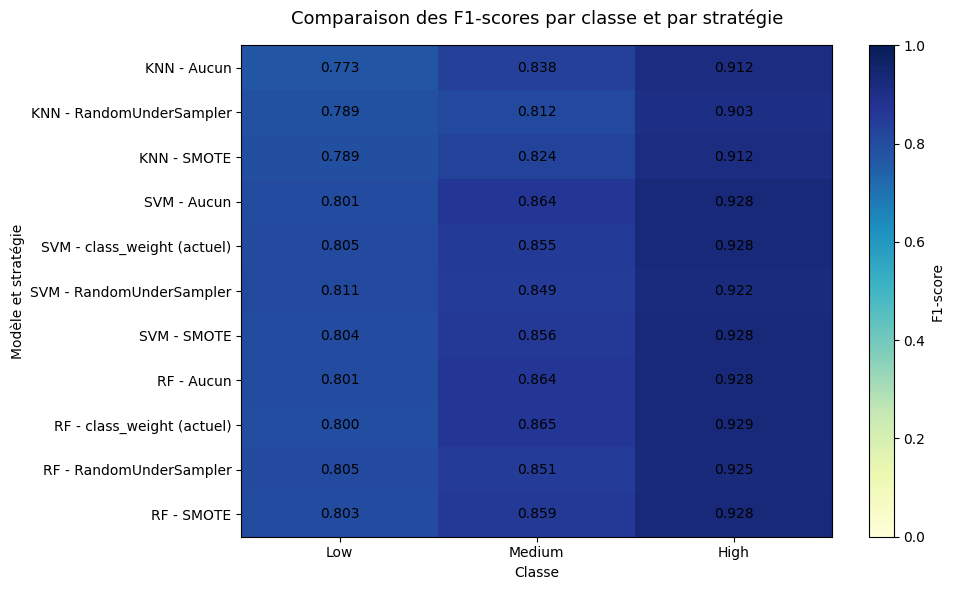

In [19]:
colonnes_f1 = ["F1_Low", "F1_Medium", "F1_High"]

# Moyenne des F1-scores sur les 3 plis
heatmap_data = cv.groupby(
    ["modele", "strategie"]
)[colonnes_f1].mean()

# Organiser les lignes par modèle et stratégie
ordre = [
    (m, s)
    for m in MODELES
    for s in STRATEGIES
    if (m, s) in heatmap_data.index
]

heatmap_data = heatmap_data.reindex(ordre)

# Noms affichés sur l'axe vertical
labels = [
    f"{m.upper()} - {NOM_STRATEGIE[s]}"
    for m, s in ordre
]

# Création de la figure
fig, ax = plt.subplots(figsize=(10, 6))

im = ax.imshow(
    heatmap_data.values,
    cmap="YlGnBu",
    aspect="auto",
    vmin=0,
    vmax=1
)

# Axes
ax.set_xticks(range(len(colonnes_f1)))
ax.set_xticklabels(["Low", "Medium", "High"])

ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)

# Afficher les valeurs dans les cellules
for i in range(len(heatmap_data)):
    for j in range(len(colonnes_f1)):
        valeur = heatmap_data.iloc[i, j]

        ax.text(
            j, i,
            f"{valeur:.3f}",
            ha="center",
            va="center",
            color="black" if valeur > 0.45 else "white",
            fontsize=10
        )

# Titres et présentation
ax.set_title(
    "Comparaison des F1-scores par classe et par stratégie",
    fontsize=13,
    pad=15
)

ax.set_xlabel("Classe")
ax.set_ylabel("Modèle et stratégie")

cbar = plt.colorbar(im, ax=ax)
cbar.set_label("F1-score")

plt.tight_layout()

plt.savefig(
    os.path.join(
        FIGURES_DIR,
        "heatmap_f1_par_classe_" + CONFIG + ".png"
    ),
    dpi=150,
    bbox_inches="tight"
)

plt.show()